# Preliminaries

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pylab as plt
import seaborn as sns
sns.set_theme(context='paper')

import matplotlib.colors as mcolors
import matplotlib.cm as cm

In [2]:
from dissipationtheory.constants import ureg, epsilon0, qe
from dissipationtheory.dissipation9a import CantileverModel, SampleModel1, SampleModel3
from dissipationtheory.dissipation9b import SampleModel1Jit, SampleModel3Jit

In [3]:
from dissipationtheory.dissipation22e import pointprobeCobject, ExptSweepConductivity, latex_float
from dissipationtheory.dissipation22e import plot_LDS, plot_LDS_zero, plot_friction, plot_friction_list

In [4]:
THIS = 'dissipation-theory--Study-80--'
figs = {}

In [5]:
obj = {}

# Cantilever and tip-sample separation

In [6]:
cantilever = CantileverModel(
    f_c = ureg.Quantity(75, 'kHz'),
    k_c = ureg.Quantity(2.8, 'N/m'), 
    V_ts = ureg.Quantity(1, 'V'), 
    R = ureg.Quantity(35, 'nm'),
    angle = ureg.Quantity(20, 'degree'),
    L = ureg.Quantity(2000, 'nm'))

Taking $h = 75 \: \mathrm{nm}$ gives $z_{\mathrm{c}} =  h + R = 110 \: \mathrm{nm}$.

In [7]:
h = ureg.Quantity(75, 'nm')

# Sweep parameters

In [8]:
N_omega = 100 # 10 or 100
N_sigma = 200 # 20 or 200

Set up an array of $\omega_{\mathrm{m}}$ values.

In [9]:
omega_m__array = ureg.Quantity(
    np.logspace(
        start=np.log10(1e1),
        stop=np.log10(1e8),
        num=N_omega), 'Hz')

Set up an array of conductivity $\sigma$ values.

In [10]:
sigma__array = ureg.Quantity(
    np.logspace(
        start=np.log10(1e-10),
        stop=np.log10(1e0),
        num=N_sigma), 'S/m')

Compute the charge density $\rho = \sigma \big/ q_e \mu$ corresponding to a mobility of $\mu = 10^{-8} \: \mathrm{m}^2 \mathrm{V}^{-1} \mathrm{s}^{-1}$.

In [11]:
mu = ureg.Quantity(1e-8, 'm^2/(V s)') 
rho__array = (sigma__array / (qe * mu)).to('1/m^3')

# Sample parameters

In [12]:
sample3 = SampleModel3(
    cantilever = cantilever,
    epsilon_s = ureg.Quantity(complex(2.8, -0.20), ''),
    sigma = sigma__array[0],
    rho = rho__array[0],
    z_r = ureg.Quantity(1, 'nm'))

sample3_jit = SampleModel3Jit(**sample3.args())

# Vary conductivity and charge density

In [13]:
expt = {}

The following simulation takes 2 to 3 minutes.

In [14]:
%%time

expt['01'] = ExptSweepConductivity('perovskite-like sample')

obj = expt['01'].calculate(
    sample3_jit, 
    h, 
    ureg.Quantity(250.,'Hz'),
    omega_m__array,
    rho__array,
    sigma__array)

CPU times: user 19h 58min 28s, sys: 10h 1min 59s, total: 1d 6h 28s
Wall time: 9h 47min 47s


In [15]:
expt['01'].df.iloc[::10]

,sigma [S/m],rho [1/cm^3],L_D [nm],rho scaled 1,rho scaled 2,rho scaled 3,omega0 [Hz],omega_c [Hz],omega_c scaled,omega_m [Hz],omega_m scaled,gamma [pN s/m],f_LDS [Hz],f_BLDS [Hz]
0,1.000000e-10,6.241509e+10,4784.333412,5.286187e-04,0.000189,0.000024,1.129409e+01,471238.898038,0.000009,"[10.0, 11.768119524349984, 13.848863713938732,...","[2.4791725875840003, 2.9175199332180544, 3.433...",1.500876,"[-0.16292275361325595, -0.16292272409774533, -...","[-0.06109581877800517, -0.06109581147198159, -..."
10,3.180626e-10,1.985190e+11,2682.657048,1.681338e-03,0.000600,0.000078,3.592227e+01,471238.898038,0.000027,"[10.0, 11.768119524349984, 13.848863713938732,...","[0.7794606555561382, 0.9172786159112827, 1.079...",1.501164,"[-0.16294852359726086, -0.1629484740876753, -0...","[-0.061105080709670495, -0.061105068568886554,..."
20,1.011638e-09,6.314148e+11,1504.211396,5.347707e-03,0.001910,0.000247,1.142553e+02,471238.898038,0.000087,"[10.0, 11.768119524349984, 13.848863713938732,...","[0.24506519497784626, 0.2883956505757428, 0.33...",1.502079,"[-0.16302683072914365, -0.16302679970941533, -...","[-0.06113356725964522, -0.0611335602930025, -0..."
30,3.217642e-09,2.008294e+12,843.436892,1.700905e-02,0.006075,0.000785,3.634034e+02,471238.898038,0.000275,"[10.0, 11.768119524349984, 13.848863713938732,...","[0.07704936658628357, 0.0906726155262843, 0.10...",1.504989,"[-0.16325699171393207, -0.1632569918484939, -0...","[-0.061218770305228536, -0.06121877281019821, ..."
40,1.023411e-08,6.387632e+12,472.929398,5.409944e-02,0.019321,0.002496,1.155850e+03,471238.898038,0.000876,"[10.0, 11.768119524349984, 13.848863713938732,...","[0.024224594161093245, 0.028507791951661605, 0...",1.514241,"[-0.16390133325408274, -0.1639013575112093, -0...","[-0.06146053606302994, -0.0614605465452986, -0..."
50,3.255089e-08,2.031667e+13,265.179551,1.720701e-01,0.061454,0.007938,3.676327e+03,471238.898038,0.002786,"[10.0, 11.768119524349984, 13.848863713938732,...","[0.00761629833273855, 0.008962950911277476, 0....",1.543643,"[-0.16557590458460128, -0.16557594436367304, -...","[-0.06208962128883669, -0.062089636467235865, ..."
60,1.035322e-07,6.461971e+13,148.690680,5.472905e-01,0.195461,0.025247,1.169302e+04,471238.898038,0.008862,"[10.0, 11.768119524349984, 13.848863713938732,...","[0.00239459121203532, 0.002817983559518974, 0....",1.636879,"[-0.16948436456213214, -0.1694844090655313, -0...","[-0.06355605712230909, -0.06355607384509987, -..."
70,3.292971e-07,2.055311e+14,83.373391,1.740726e+00,0.621688,0.080301,3.719112e+04,471238.898038,0.028186,"[10.0, 11.768119524349984, 13.848863713938732,...","[0.000752867971060033, 0.0008859840269489334, ...",1.930529,"[-0.17738289867598903, -0.17738293608822653, -...","[-0.06651837548674766, -0.06651838952070506, -..."
80,1.047371e-06,6.537175e+14,46.748877,5.536598e+00,1.977356,0.255406,1.182910e+05,471238.898038,0.089650,"[10.0, 11.768119524349984, 13.848863713938732,...","[0.00023670436064378617, 0.000278556520799092,...",2.832878,"[-0.19090793162648728, -0.19090795476942152, -...","[-0.07159041133826163, -0.07159042001736728, -..."
90,3.331295e-06,2.079231e+15,26.212890,1.760985e+01,6.289231,0.812352,3.762395e+05,471238.898038,0.285145,"[10.0, 11.768119524349984, 13.848863713938732,...","[7.442069061444509e-05, 8.757915822354608e-05,...",5.326444,"[-0.21182579566735085, -0.21182580585563263, -...","[-0.07943465886821456, -0.07943466268886605, -..."


## LDS $\Delta f_{\mathrm{LDS}}$ versus $\omega_{\mathrm{m}}$ spectra

In [16]:
plt.rcParams['text.usetex'] = True

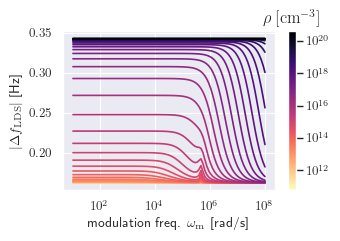

In [17]:
figs['01'] = plot_LDS(expt['01'], n=5, scaled=False)

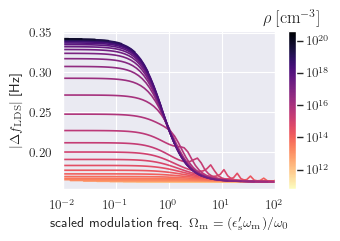

In [18]:
figs['02'] = plot_LDS(expt['01'], n=5, scaled=True)
figs['02'].axes[0].set_xlim([1e-2,1e2]);

## LDS $\Delta f_{\mathrm{LDS}}(\omega_{\mathrm{m}} = 0)$ versus charge density 

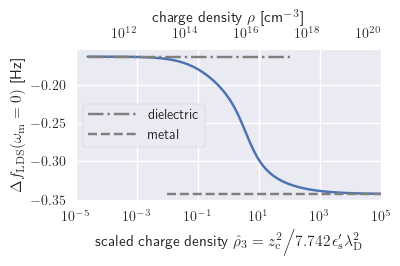

In [19]:
figs['03'] = plot_LDS_zero(expt['01'], obj)
figs['03'].axes[0].set_xlim([1e-5,1e5]);

## Friction

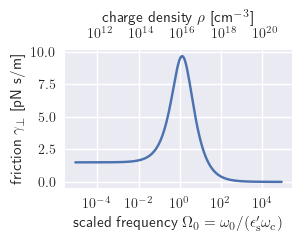

In [20]:
figs['04'] = plot_friction(expt['01'])

Vary $\epsilon_{\mathrm{s}}^{\prime\prime}$. \
The following similation is expected to take 12 to 15 minutes to run.

In [21]:
%%time

epsilon_s_start = sample3.epsilon_s
epsilon_list = [20-0.02j, 20-0.2j, 20-0.5j, 20-1j]

objs = {}
for key, epsilon_s in zip(['02a', '02b', '02c', '02d'], epsilon_list):
    
    sample3.epsilon_s = ureg.Quantity(epsilon_s, '')
    sample3_jit = SampleModel3Jit(**sample3.args())

    expt[key] = ExptSweepConductivity('perovskite-like sample')
    objs[key] = expt[key].calculate(
        sample3_jit, 
        h, 
        ureg.Quantity(250.,'Hz'),
        omega_m__array,
        rho__array,
        sigma__array)

sample3.epsilon_s = epsilon_s_start             # reset it
sample3_jit = SampleModel3Jit(**sample3.args()) # reset it

CPU times: user 1d 17h 6min 42s, sys: 20h 30min 13s, total: 2d 13h 36min 55s
Wall time: 23h 25min 48s


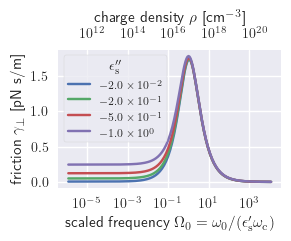

In [22]:
figs['05'] = plot_friction(expt['02a'])

with plt.style.context('seaborn-v0_8'):

    for key in ['02b', '02c', '02d']:

        figs['05'].axes[0].semilogx(
            expt[key].df['omega_c scaled'].values,
            np.array([row for row in expt[key].df['gamma [pN s/m]']]))

    figs['05'].axes[0].legend(
        [latex_float(ep.imag) for ep in epsilon_list], 
        title=r'$\epsilon_{\mathrm{s}}^{\prime\prime}$',
        fontsize=8,
        title_fontsize=10,
        frameon=True)

Vary $\mu$. \
The following similation is expected to take 12 to 15 minutes to run.

In [23]:
%%time

rho__array__start = rho__array # save it
mu_list = [ureg.Quantity(val, 'cm^2/(V s)') for val in [1e-6, 1e-4, 1e-3, 1e-2]]

for key, mu in zip(['03a', '03b', '03c', '03d'], mu_list):
    
    rho__array = (sigma__array / (qe * mu)).to('1/m^3')
    
    expt[key] = ExptSweepConductivity('perovskite-like sample')
    
    objs[key] = expt[key].calculate(
        sample3_jit, 
        h, 
        ureg.Quantity(250.,'Hz'),
        omega_m__array,
        rho__array,
        sigma__array)    
    
rho__array = rho__array__start # reset it

CPU times: user 2h 37min 53s, sys: 14min 36s, total: 2h 52min 30s
Wall time: 22min 1s


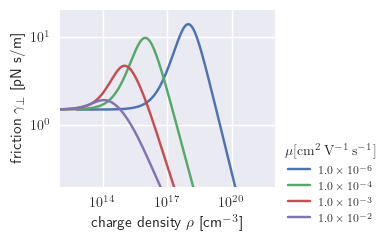

In [24]:
figs['06'] = plot_friction_list(expt, ['03a', '03b', '03c', '03d'])

figs['06'].axes[0].legend(
    [latex_float(mu.to('cm^2/(V s)').magnitude) for mu in mu_list], 
    title=r'$\mu [\mathrm{cm}^{2} \: \mathrm{V}^{-1} \: \mathrm{s}^{-1}]$',
    fontsize=8,
    title_fontsize=10,
    frameon=False,
    bbox_to_anchor=(1, 0.3))

figs['06'].axes[0].set_xlim([1e12,1e22]);
figs['06'].axes[0].set_ylim([2e-1,2e1]);  # new
figs['06'].set_size_inches((4.00, 2.50))
figs['06'].tight_layout()

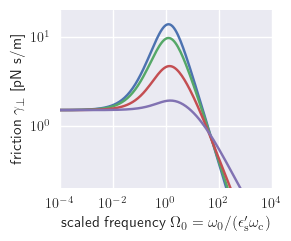

In [25]:
figs['07'] = plot_friction_list(expt, ['03a', '03b', '03c', '03d'], scaled=True)

#figs['07'].axes[0].legend(
#    [latex_float(mu.to('cm^2/(V s)').magnitude) for mu in mu_list], 
#    title=r'$\mu [\mathrm{cm}^{2} \: \mathrm{V}^{-1} \: \mathrm{s}^{-1}]$',
#    fontsize=8,
#    title_fontsize=10,
#    frameon=False,
#    bbox_to_anchor=(1, 0.75))

figs['07'].axes[0].set_xlim([1e-4,1e+4]);
figs['07'].axes[0].set_ylim([2e-1,2e1]);  # new
figs['07'].set_size_inches((3.00, 2.50))
figs['07'].tight_layout()

# Conclusions

Comparing the newest version of the theory to the prior version,

- The friction is 2x larger
- The LDS spectra show wiggles near the cantilever frequency
- The LDS spectra are significantly slower to compute

::: {.content-hidden when-format="html"}

# Save the figures

In [26]:
if 1:
    for num in figs.keys():
        figname = THIS + "Fig-" + num
        print("saving", figname)
        figs[num].savefig(figname + '.png', dpi=300)
        figs[num].savefig(figname + '.pdf')

saving dissipation-theory--Study-80--Fig-01
saving dissipation-theory--Study-80--Fig-02
saving dissipation-theory--Study-80--Fig-03
saving dissipation-theory--Study-80--Fig-04
saving dissipation-theory--Study-80--Fig-05
saving dissipation-theory--Study-80--Fig-06
saving dissipation-theory--Study-80--Fig-07


# Formatting notes

The header at the top of this file is for creating a nicely-formatted `.html` document using the program `quarto` ([link](https://quarto.org/)).  During development you can run the following command to render and display an `html` file on the fly.

    quarto preview dissipation-theory--Study-80.ipynb

When you are done developing this notebook, run  `quarto` from the command line as follows to create a nicely-formated `.html` version of the notebook.

    quarto render dissipation-theory--Study-80.ipynb && open dissipation-theory--Study-80.html
    
:::